<a href="https://colab.research.google.com/github/mohany606/Linear-Models-and-Support-Vector-Machines-from-Scratch/blob/main/ML_Assigmment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part A: Data:**

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.datasets import (
    load_diabetes,
    load_breast_cancer,
    load_digits,
    load_iris
)
# 1. Diabetes
diabetes = load_diabetes(scaled=False)
X_diabetes = diabetes.data
y_diabetes = diabetes.target
# 2. Breast Cancer
cancer = load_breast_cancer()
X_cancer = cancer.data
y_cancer = 1 - cancer.target  # Malignant = 1
# 3. Digits
digits = load_digits()
X_digits = digits.data / 16.0
y_digits = digits.target
# 4. Iris
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
def split_data(X, y, regression=False):
    stratify = None if regression else y
    # First split
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=stratify
    )
    # Second split
    stratify_temp = None if regression else y_temp

    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp,
        test_size=0.25,
        random_state=42,
        stratify=stratify_temp
    )

    return X_train, X_val, X_test, y_train, y_val, y_test


In [ ]:
datasets = {
    "Diabetes": (X_diabetes, y_diabetes, True),
    "Breast Cancer": (X_cancer, y_cancer, False),
    "Digits": (X_digits, y_digits, False),
    "Iris": (X_iris, y_iris, False)
}

splits = {}

for name, (X, y, regression) in datasets.items():
    splits[name] = split_data(X, y, regression)

    X_train, X_val, X_test, y_train, y_val, y_test = splits[name]
    print(f"\n{name}")
    print("Train:", X_train.shape)
    print("Validation:", X_val.shape)
    print("Test:", X_test.shape)

    if not regression:
        print("Train class counts:", np.bincount(y_train))
        print("Validation class counts:", np.bincount(y_val))
        print("Test class counts:", np.bincount(y_test))



Diabetes
Train: (264, 10)
Validation: (89, 10)
Test: (89, 10)

Breast Cancer
Train: (341, 30)
Validation: (114, 30)
Test: (114, 30)
Train class counts: [214 127]
Validation class counts: [71 43]
Test class counts: [72 42]

Digits
Train: (1077, 64)
Validation: (360, 64)
Test: (360, 64)
Train class counts: [106 109 107 109 109 109 109 107 104 108]
Validation class counts: [36 37 35 37 36 36 36 36 35 36]
Test class counts: [36 36 35 37 36 37 36 36 35 36]

Iris
Train: (90, 4)
Validation: (30, 4)
Test: (30, 4)
Train class counts: [30 30 30]
Validation class counts: [10 10 10]
Test class counts: [10 10 10]


In [ ]:

class Standardizer:
    def fit(self, X):
        self.mean = np.mean(X, axis=0)

        #each column feature
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1
        return self
    def transform(self, X):
        return (X - self.mean) / self.std

scaler = Standardizer()
#Why not call fit() separately for validation and testing?
#Because that would mean using different means and standard deviations for different sets.
#We want all three sets to use the same transformation.

def add_bias(X):
    return np.c_[np.ones(X.shape[0]), X]

# Preprocess each dataset separately
processed_data = {}
scalers = {}
for name in datasets:

    X_train, X_val, X_test, y_train, y_val, y_test = splits[name]

    if name == "Digits":
        # Digits are already divided by 16.
        # NO standardize them.
        X_train_processed = X_train
        X_val_processed = X_val
        X_test_processed = X_test

    else:
        # Fit using training data only
        scaler = Standardizer()
        scaler.fit(X_train)

        X_train_processed = scaler.transform(X_train)
        X_val_processed = scaler.transform(X_val)
        X_test_processed = scaler.transform(X_test)

        scalers[name] = scaler

        train_mean = np.mean(X_train_processed, axis=0)
        train_std = np.std(X_train_processed, axis=0)

        nonconstant = np.std(X_train, axis=0) > 0

        assert np.all(np.abs(train_mean) < 1e-9)
        assert np.allclose(train_std[nonconstant], 1, atol=1e-9)

        print(f"\n{name} Standardizer verification:")
        print("Maximum absolute training mean:",
              np.max(np.abs(train_mean)))
        print("Training standard deviations:", train_std)

    # Add bias to all three splits
    X_train_final = add_bias(X_train_processed)
    X_val_final = add_bias(X_val_processed)
    X_test_final = add_bias(X_test_processed)

    # Save everything together
    processed_data[name] = (
        X_train_final,
        X_val_final,
        X_test_final,
        y_train,
        y_val,
        y_test
    )

print("\nAll datasets preprocessed successfully.")





Diabetes Standardizer verification:
Maximum absolute training mean: 2.2372676102294822e-15
Training standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Breast Cancer Standardizer verification:
Maximum absolute training mean: 5.108979384873301e-15
Training standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]

Iris Standardizer verification:
Maximum absolute training mean: 1.2927930331190711e-15
Training standard deviations: [1. 1. 1. 1.]

All datasets preprocessed successfully.


In [ ]:
#mean squared error
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)
#Root Mean Squared Error
def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))
#R² — Coefficient of Determination
def r2(y_true, y_pred):
    s = np.sum((y_true - y_pred) ** 2)
    sm = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (s / sm)
#Accuracy
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)
#Confusion Matrix
def confusion_matrix(y_true, y_pred, m):#m:number  of classes
    cm = np.zeros((m, m), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)#y_true, y_pred:m[i,j]
    return cm

def classification_metrics(cm):
    K = cm.shape[0]
    # True positives: diagonal
    TP = np.diag(cm)

    # Total predicted (column sums) TP+FP
    predicted = np.sum(cm, axis=0)

    # Total actual (row sums)TP+Fn
    actual = np.sum(cm, axis=1)

    # Precision
    # If a class is never predicted, precision = 0
    precision = np.divide(
        TP,
        predicted,
        out=np.zeros(K, dtype=float),
        where=predicted != 0
    )

    # Recall
    recall = np.divide(
        TP,
        actual,
        out=np.zeros(K, dtype=float),
        where=actual != 0
    )

    # F1-score
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(K, dtype=float),
        where=(precision + recall) != 0
    )

    # Macro averages
    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    }



In [ ]:

from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix as sk_confusion_matrix,
    precision_recall_fscore_support
)

rng = np.random.default_rng(42)

# Generate random classification labels
K = 4
N = 500

y_true = rng.integers(0, K, size=N)
y_pred = rng.integers(0, K, size=N)


cm = confusion_matrix(y_true, y_pred, K)
cm_sk = sk_confusion_matrix(
    y_true, y_pred,
    labels=np.arange(K) #[0, 1, 2, 3]
)

assert np.array_equal(cm, cm_sk) #If yes, the code continues.
#If no, Python raises an AssertionError and stops.


acc = accuracy(y_true, y_pred)
acc_sk = accuracy_score(y_true, y_pred)

assert abs(acc - acc_sk) < 1e-12 #tolerance error


our_metrics = classification_metrics(cm)

# sklearn metrics
p_sk, r_sk, f1_sk, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)
#np.allclose() compares two arrays element by element
assert np.allclose(our_metrics["precision"], p_sk, atol=1e-12)

assert np.allclose(our_metrics["recall"], r_sk, atol=1e-12)

assert np.allclose(our_metrics["f1"], f1_sk, atol=1e-12)

assert abs(our_metrics["macro_precision"] - np.mean(p_sk)) < 1e-12

assert abs( our_metrics["macro_recall"] - np.mean(r_sk)) < 1e-12

assert abs( our_metrics["macro_f1"] - np.mean(f1_sk)) < 1e-12

print("All classification metrics ")

# Generate random regression values
y_true_reg = rng.normal(size=500)
y_pred_reg = rng.normal(size=500)

# MSE
our_mse = mse(y_true_reg, y_pred_reg)
sk_mse = mean_squared_error(y_true_reg, y_pred_reg)

# RMSE
our_rmse = rmse(y_true_reg, y_pred_reg)
sk_rmse = np.sqrt(sk_mse)

# R2
our_r2 = r2(y_true_reg, y_pred_reg)
sk_r2 = r2_score(y_true_reg, y_pred_reg)

assert abs(our_mse - sk_mse) < 1e-12
assert abs(our_rmse - sk_rmse) < 1e-12
assert abs(our_r2 - sk_r2) < 1e-12

print("All regression metrics")



All classification metrics 
All regression metrics


In [ ]:

def grad_check(f, grad, w, eps=1e-5, num_checks=None):

    # Calculate analytical gradient
    g_analytic = grad(w)

    # Initialize numerical gradient:with the same shape as w, but filled with zeros.
    g_numeric = np.zeros_like(w, dtype=float)

    # It converts an array into a one-dimensional array.
    w_flat = w.reshape(-1)
    g_flat = g_numeric.reshape(-1)
    #If the user doesn't specify how many weights to check,
    #or requests at least as many checks as there are weights, check all weights.
    if num_checks is None or num_checks >= w.size:
        indices = np.arange(w.size)
    else:
        rng = np.random.default_rng(42)
        indices = rng.choice(
            w.size,
            size=num_checks,
            replace=False
        )

    #numerical gradient
    for i in indices:
        w_plus = w.copy()
        w_minus = w.copy()
        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps
        g_flat[i] = (f(w_plus) - f(w_minus) ) / (2 * eps)

    # Compare only the selected entries
    analytic_selected = g_analytic.flat[indices]
    numeric_selected = g_numeric.flat[indices]

    # np.linalg.norm() calculates the Euclidean length of this difference
    numerator = np.linalg.norm(
        analytic_selected - numeric_selected
    )

    denominator = max(
        np.linalg.norm(analytic_selected),
        np.linalg.norm(numeric_selected),
        1e-12
    )

    relative_error = numerator / denominator

    return relative_error


# **Part B :Linear Regression:**

# **Part C : Logistic Regression:**

#11-Derivation and stable implementation:

In [ ]:
X_train, X_val, X_test, y_train, y_val, y_test = processed_data["Breast Cancer"]
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Train labels:", np.unique(y_train, return_counts=True))

Train: (341, 31)
Validation: (114, 31)
Test: (114, 31)
Train labels: (array([0, 1]), array([214, 127]))


In [ ]:
def sigmoid(z):
    result = np.empty_like(z, dtype=float)
    positive = z >= 0
    result[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z)
    return result

def logistic_loss(X, y, w, lam):
    z = X @ w
    loss = np.mean(np.logaddexp(0, z) - y * z)
    reg = (lam / 2) * np.sum(w[1:] ** 2)
    return loss + reg

def logistic_gradient(X, y, w, lam):
    p = sigmoid(X @ w)
    grad = X.T @ (p - y) / len(y)
    grad[1:] += lam * w[1:]
    return grad

In [ ]:
z = np.array([800.0, -800.0])
y_test_values = np.array([1.0, 0.0])
p = sigmoid(z)
stable_loss = np.logaddexp(0, z) - y_test_values * z

print("Sigmoid:", p)
print("Stable loss:", stable_loss)

with np.errstate(over='ignore', divide='ignore', invalid='ignore'):
    naive_p = 1 / (1 + np.exp(-z))
    naive_loss = -(
        y_test_values * np.log(naive_p) +
        (1 - y_test_values) * np.log(1 - naive_p)
    )
print("Naive probabilities:", naive_p)
print("Naive loss:", naive_loss)

Sigmoid: [1. 0.]
Stable loss: [0. 0.]
Naive probabilities: [1. 0.]
Naive loss: [nan nan]


In [ ]:
rng = np.random.default_rng(42)
w_random = rng.normal(0, 0.1, X_train.shape[1])
lam = 0.1
f = lambda w: logistic_loss(X_train, y_train, w, lam)
grad = lambda w: logistic_gradient(X_train, y_train, w, lam)
error = grad_check(f, grad, w_random)
print("Gradient relative error:", error)

Gradient relative error: 1.899324633360124e-11


#12-Training and regularization:

In [ ]:
def train_logistic(X_train, y_train, X_val, y_val,lam, learning_rate, epochs):
    w = np.zeros(X_train.shape[1])
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):
        grad = logistic_gradient(X_train, y_train, w, lam)
        w = w - learning_rate * grad

        train_loss = logistic_loss(X_train, y_train, w, lam)
        val_loss = logistic_loss(X_val, y_val, w, lam)

        train_pred = (sigmoid(X_train @ w) >= 0.5).astype(int)
        val_pred = (sigmoid(X_val @ w) >= 0.5).astype(int)

        train_acc = accuracy(y_train, train_pred)
        val_acc = accuracy(y_val, val_pred)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

    return w, train_losses, val_losses, train_accuracies, val_accuracies

In [ ]:
lambdas = [0, 1e-3, 1e-2, 1e-1, 1]
results = {}
for lam in lambdas:
    w, train_losses, val_losses, train_accs, val_accs = train_logistic(
        X_train, y_train,
        X_val, y_val,
        lam=lam,
        learning_rate=0.5,
        epochs=3000
    )
    results[lam] = {
        "w": w,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs
    }
print("All lambda experiments completed.")

All lambda experiments completed.


In [ ]:
for lam in lambdas:
    w = results[lam]["w"]

    train_pred = (sigmoid(X_train @ w) >= 0.5).astype(int)
    val_pred = (sigmoid(X_val @ w) >= 0.5).astype(int)

    train_acc = accuracy(y_train, train_pred)
    val_acc = accuracy(y_val, val_pred)

    val_loss = results[lam]["val_losses"][-1]

    weight_norm = np.linalg.norm(w[1:])

    print(f"\nLambda = {lam}")
    print("Train Accuracy:", train_acc)
    print("Validation Accuracy:", val_acc)
    print("Validation Loss:", val_loss)
    print("||w[1:]||:", weight_norm)


Lambda = 0
Train Accuracy: 0.9941348973607038
Validation Accuracy: 0.9736842105263158
Validation Loss: 0.08419249601904283
||w[1:]||: 8.132231477398316

Lambda = 0.001
Train Accuracy: 0.9882697947214076
Validation Accuracy: 0.9736842105263158
Validation Loss: 0.08620739680111857
||w[1:]||: 5.099928324496716

Lambda = 0.01
Train Accuracy: 0.9853372434017595
Validation Accuracy: 0.9736842105263158
Validation Loss: 0.11000996461449458
||w[1:]||: 2.3257488203983168

Lambda = 0.1
Train Accuracy: 0.9736070381231672
Validation Accuracy: 0.9736842105263158
Validation Loss: 0.20266500651013983
||w[1:]||: 1.1055473475911581

Lambda = 1
Train Accuracy: 0.9384164222873901
Validation Accuracy: 0.956140350877193
Validation Loss: 0.38966789760047005
||w[1:]||: 0.4414849755616663


In [ ]:
best_lambda = min(
    lambdas,
    key=lambda lam: results[lam]["val_losses"][-1]
)
best_w = results[best_lambda]["w"]
test_pred = (sigmoid(X_test @ best_w) >= 0.5).astype(int)
test_acc = accuracy(y_test, test_pred)

print("Best Lambda:", best_lambda)
print("Test Accuracy:", test_acc)

Best Lambda: 0
Test Accuracy: 0.9736842105263158


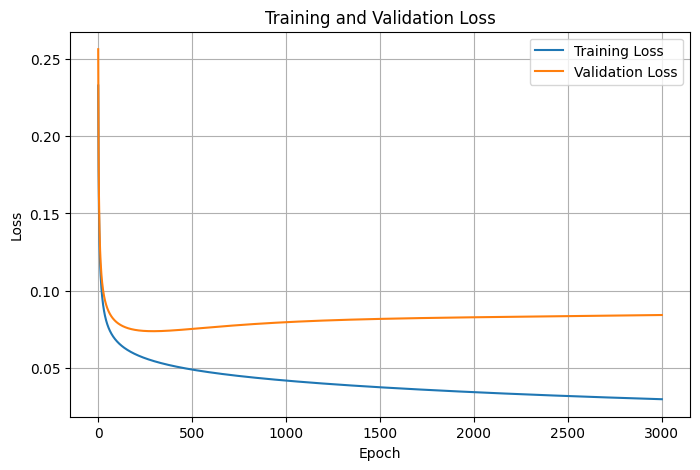

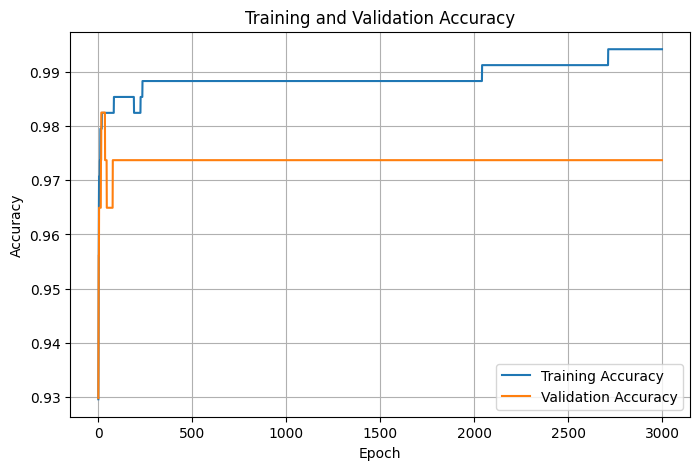

In [ ]:
import matplotlib.pyplot as plt
best_results = results[best_lambda]
epochs_range = range(1, 3001)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, best_results["train_losses"], label="Training Loss")
plt.plot(epochs_range, best_results["val_losses"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(epochs_range, best_results["train_accs"], label="Training Accuracy")
plt.plot(epochs_range, best_results["val_accs"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [ ]:
learning_rates = [0.01, 0.1, 1, 5, 20]
lr_results = {}

for lr in learning_rates:
    w, train_losses, val_losses, train_accs, val_accs = train_logistic(
        X_train, y_train,
        X_val, y_val,
        lam=0.01,
        learning_rate=lr,
        epochs=1000)

    lr_results[lr] = train_losses[-1]

    print("Learning Rate:", lr)
    print("Final Training Loss:", train_losses[-1])

Learning Rate: 0.01
Final Training Loss: 0.11628901770966023
Learning Rate: 0.1
Final Training Loss: 0.09831148320292545
Learning Rate: 1
Final Training Loss: 0.09811173825937314
Learning Rate: 5
Final Training Loss: 0.09811173825907171
Learning Rate: 20
Final Training Loss: 0.15782300657680046


#13-Separability:

In [ ]:
w_sep = np.zeros(X_train.shape[1])
weight_norms = []
train_losses = []

for epoch in range(20000):
    grad = logistic_gradient(X_train, y_train, w_sep, lam=0)
    w_sep = w_sep - 0.5 * grad
    weight_norms.append(np.linalg.norm(w_sep[1:]))
    train_losses.append(logistic_loss(X_train, y_train, w_sep, lam=0))

print("Final Weight Norm:", weight_norms[-1])
print("Final Training Loss:", train_losses[-1])


Final Weight Norm: 19.07910409109684
Final Training Loss: 0.011458238949846756


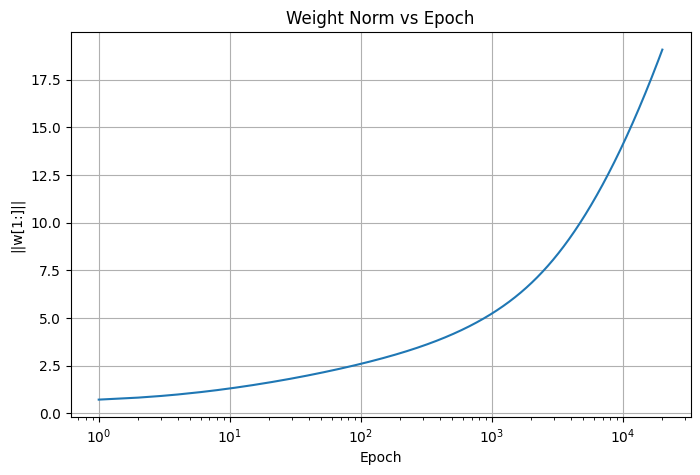

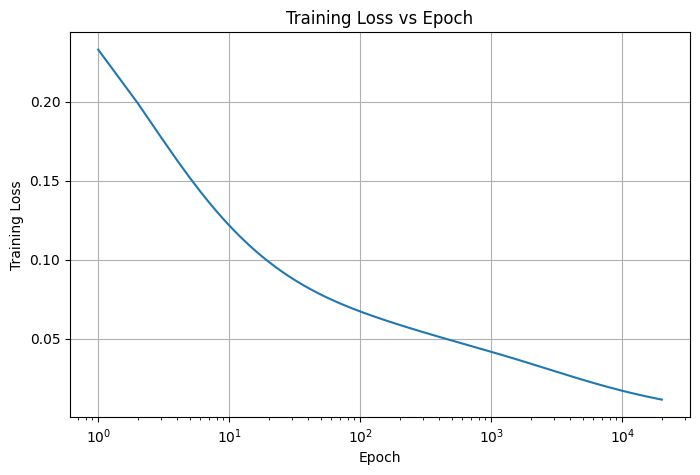

In [ ]:
epochs_range = np.arange(1, 20001)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, weight_norms)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("||w[1:]||")
plt.title("Weight Norm vs Epoch")
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_losses)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs Epoch")
plt.grid()
plt.show()

#14-Off-the-shelf comparison:


In [ ]:
from sklearn.linear_model import LogisticRegression
sklearn_results = {}

for lam in lambdas:
    if lam == 0:
        model = LogisticRegression(
            penalty=None,
            max_iter=100000)
    else:
        C = 1 / (lam * len(y_train))
        model = LogisticRegression(
            C=C,
            max_iter=100000)

    model.fit(X_train[:, 1:], y_train)

    train_acc = model.score(X_train[:, 1:], y_train)
    val_acc = model.score(X_val[:, 1:], y_val)
    test_acc = model.score(X_test[:, 1:], y_test)

    sklearn_results[lam] = model

    print(f"Lambda = {lam}")
    print(f"C = {'None' if lam == 0 else C}")
    print(f"Train Accuracy = {train_acc:.4f}")
    print(f"Validation Accuracy = {val_acc:.4f}")
    print(f"Test Accuracy = {test_acc:.4f}")
    print()

Lambda = 0
C = None
Train Accuracy = 1.0000
Validation Accuracy = 0.9649
Test Accuracy = 0.9649

Lambda = 0.001
C = 2.9325513196480935
Train Accuracy = 0.9883
Validation Accuracy = 0.9737
Test Accuracy = 0.9737

Lambda = 0.01
C = 0.29325513196480935
Train Accuracy = 0.9853
Validation Accuracy = 0.9737
Test Accuracy = 0.9825

Lambda = 0.1
C = 0.029325513196480937
Train Accuracy = 0.9736
Validation Accuracy = 0.9737
Test Accuracy = 0.9737

Lambda = 1
C = 0.002932551319648094
Train Accuracy = 0.9384
Validation Accuracy = 0.9561
Test Accuracy = 0.9211



In [ ]:
lam = 0.01
model = LogisticRegression(
    C=1 / (lam * len(y_train)),
    tol=1e-12,
    max_iter=100000)

model.fit(X_train[:, 1:], y_train)
w_sklearn = np.concatenate([model.intercept_, model.coef_.ravel()])
w_ours = results[lam]["w"]

relative_error = np.linalg.norm(w_ours - w_sklearn) / np.linalg.norm(w_sklearn)
pred_ours = (sigmoid(X_test @ w_ours) >= 0.5).astype(int)
pred_sklearn = model.predict(X_test[:, 1:])

print("Our weights:", w_ours[:5])
print("Sklearn weights:", w_sklearn[:5])
print("Relative Error:", relative_error)
print("Predictions Agree:", np.array_equal(pred_ours, pred_sklearn))

Our weights: [-0.42381639  0.45272781  0.4263065   0.43913875  0.43804957]
Sklearn weights: [-0.42381669  0.45272814  0.42630667  0.43913901  0.43804956]
Relative Error: 5.389606856862711e-07
Predictions Agree: True


In [ ]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
C_results = []

for C in C_values:
    model = LogisticRegression(C=C, max_iter=100000)
    model.fit(X_train[:, 1:], y_train)
    C_results.append([
        C,
        model.score(X_train[:, 1:], y_train),
        model.score(X_val[:, 1:], y_val),
        model.score(X_test[:, 1:], y_test)])

print("C\t\tTrain Acc\tVal Acc\t\tTest Acc")
for row in C_results:
    print(f"{row[0]}\t\t{row[1]:.4f}\t\t{row[2]:.4f}\t\t{row[3]:.4f}")

C		Train Acc	Val Acc		Test Acc
0.001		0.8798		0.9035		0.8684
0.01		0.9501		0.9649		0.9474
0.1		0.9795		0.9825		0.9825
1		0.9883		0.9737		0.9737
10		0.9971		0.9649		0.9649
100		1.0000		0.9561		0.9561
1000		1.0000		0.9474		0.9561


In [ ]:
import time
C = 1 / (0.01 * len(y_train))
solvers = ["lbfgs", "liblinear", "saga"]
solver_results = {}

for solver in solvers:
    model = LogisticRegression(
        C=C,
        solver=solver,
        tol=1e-8,
        max_iter=100000)

    start = time.perf_counter()
    model.fit(X_train[:, 1:], y_train)
    elapsed = time.perf_counter() - start
    coefficients = np.concatenate([model.intercept_, model.coef_.ravel()])
    solver_results[solver] = coefficients

    print(f"Solver: {solver}")
    print("Iterations:", model.n_iter_[0])
    print("Time:", elapsed)
    print("First 5 coefficients:", coefficients[:5])
    print()

print("Coefficient differences from lbfgs:")

for solver in solvers:
    difference = np.linalg.norm(
        solver_results[solver] - solver_results["lbfgs"]
    )
    print(solver, ":", difference)

Solver: lbfgs
Iterations: 28
Time: 0.11134429300000193
First 5 coefficients: [-0.42381676  0.45272816  0.42630668  0.43913902  0.43804954]

Solver: liblinear
Iterations: 10
Time: 0.012745077000090532
First 5 coefficients: [-0.28790001  0.44114212  0.41979197  0.42895102  0.44979909]

Solver: saga
Iterations: 778
Time: 0.33155330399995364
First 5 coefficients: [-0.42381643  0.45272774  0.42630662  0.43913868  0.43804958]

Coefficient differences from lbfgs:
lbfgs : 0.0
liblinear : 0.16265262175249076
saga : 1.944131975494523e-06


#15-Evaluation beyond accuracy:

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
w_001 = results[0.01]["w"]

test_scores = sigmoid(X_test @ w_001)
test_pred_05 = (test_scores >= 0.5).astype(int)

cm_05 = confusion_matrix(y_test, test_pred_05)
precision_05 = precision_score(y_test, test_pred_05)
recall_05 = recall_score(y_test, test_pred_05)
f1_05 = f1_score(y_test, test_pred_05)

print("Confusion Matrix:")
print(cm_05)
print("Precision:", precision_05)
print("Recall:", recall_05)
print("F1 Score:", f1_05)

Confusion Matrix:
[[72  0]
 [ 2 40]]
Precision: 1.0
Recall: 0.9523809523809523
F1 Score: 0.975609756097561


AUC from scratch: 0.9957418932197839
AUC from sklearn: 0.9957418932197838
Absolute Difference: 1.1102230246251565e-16


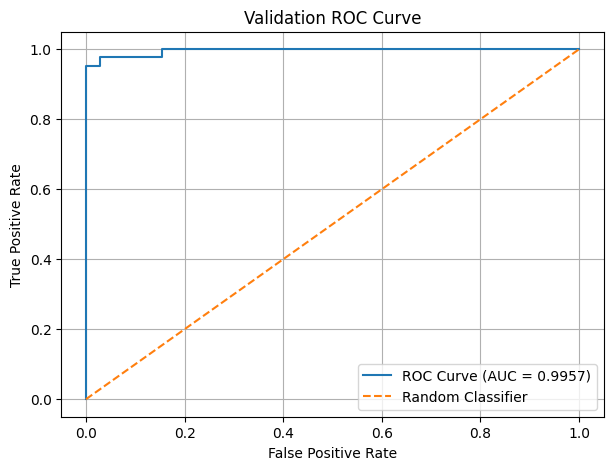

In [ ]:
from sklearn.metrics import roc_auc_score
val_scores = sigmoid(X_val @ w_001)

sorted_indices = np.argsort(-val_scores)
sorted_scores = val_scores[sorted_indices]
sorted_y = y_val[sorted_indices]

cum_tp = np.cumsum(sorted_y)
cum_fp = np.cumsum(1 - sorted_y)

distinct_indices = np.where(np.diff(sorted_scores) != 0)[0]
distinct_indices = np.append(distinct_indices, len(sorted_scores) - 1)

tp = cum_tp[distinct_indices]
fp = cum_fp[distinct_indices]

tpr = np.concatenate([[0], tp / np.sum(y_val)])
fpr = np.concatenate([[0], fp / np.sum(1 - y_val)])

auc_scratch = np.trapezoid(tpr, fpr)
auc_sklearn = roc_auc_score(y_val, val_scores)

print("AUC from scratch:", auc_scratch)
print("AUC from sklearn:", auc_sklearn)
print("Absolute Difference:", abs(auc_scratch - auc_sklearn))

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_scratch:.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [ ]:
tau = np.min(val_scores[y_val == 1])

val_pred_tau = (val_scores >= tau).astype(int)
val_recall_tau = recall_score(y_val, val_pred_tau)

test_pred_tau = (test_scores >= tau).astype(int)

cm_tau = confusion_matrix(y_test, test_pred_tau)
precision_tau = precision_score(y_test, test_pred_tau, zero_division=0)
recall_tau = recall_score(y_test, test_pred_tau)

print("Selected Threshold:", tau)
print("Validation Recall:", val_recall_tau)
print("\nTest Confusion Matrix at tau:")
print(cm_tau)
print("Test Precision:", precision_tau)
print("Test Recall:", recall_tau)

Selected Threshold: 0.14602532493304418
Validation Recall: 1.0

Test Confusion Matrix at tau:
[[66  6]
 [ 1 41]]
Test Precision: 0.8723404255319149
Test Recall: 0.9761904761904762


#16-The boundary in original coordinates:

In [ ]:
feature_indices = [0, 1]

X_train_raw = splits["Breast Cancer"][0][:, feature_indices]
X_val_raw = splits["Breast Cancer"][1][:, feature_indices]
X_test_raw = splits["Breast Cancer"][2][:, feature_indices]

scaler_2 = Standardizer()
scaler_2.fit(X_train_raw)

X_train_2 = add_bias(scaler_2.transform(X_train_raw))
X_val_2 = add_bias(scaler_2.transform(X_val_raw))
X_test_2 = add_bias(scaler_2.transform(X_test_raw))

print("Train shape:", X_train_2.shape)
print("Mean:", scaler_2.mean)
print("Std:", scaler_2.std)

Train shape: (341, 3)
Mean: [14.16341935 19.42876833]
Std: [3.5940381  4.35476066]


In [ ]:
w_2 = np.zeros(X_train_2.shape[1])
for epoch in range(5000):
    grad = logistic_gradient(X_train_2, y_train, w_2, lam=0)
    w_2 = w_2 - 0.5 * grad
print("Weights:", w_2)

Weights: [-0.7271724   3.65679417  1.00987153]


In [ ]:
w_orig = np.zeros_like(w_2)
w_orig[1:] = w_2[1:] / scaler_2.std
w_orig[0] = w_2[0] - np.sum(
    w_2[1:] * scaler_2.mean / scaler_2.std)
print("Original weights:", w_orig)

Original weights: [-19.64344417   1.01746116   0.23190058]


In [ ]:
scores_standardized = X_test_2 @ w_2
scores_original = add_bias(X_test_raw) @ w_orig
max_difference = np.max(
    np.abs(scores_standardized - scores_original))
print("Maximum difference:", max_difference)
print("Verification passed:", max_difference < 1e-9)

Maximum difference: 3.552713678800501e-15
Verification passed: True


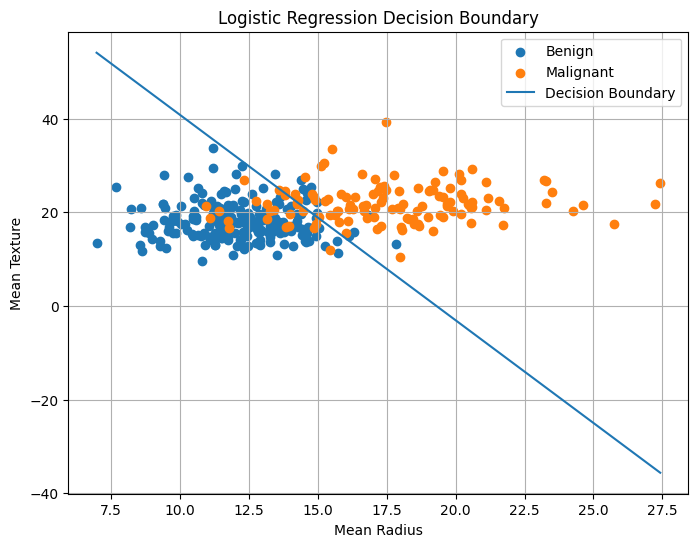

In [ ]:
x_values = np.linspace(
    X_train_raw[:, 0].min(),
    X_train_raw[:, 0].max(),
    100)

y_values = -(w_orig[0] + w_orig[1] * x_values) / w_orig[2]
plt.figure(figsize=(8, 6))
plt.scatter(
    X_train_raw[y_train == 0, 0],
    X_train_raw[y_train == 0, 1],
    label="Benign")

plt.scatter(
    X_train_raw[y_train == 1, 0],
    X_train_raw[y_train == 1, 1],
    label="Malignant")

plt.plot(x_values, y_values, label="Decision Boundary")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.grid()
plt.show()

# **Part D : Softmax Classifier:**

In [ ]:

# Retrieve the PROCESSED Digits dataset
X_train_final, X_val_final, X_test_final, y_train, y_val, y_test = processed_data["Digits"]

def softmax(S):
    S_shifted = S - np.max(S, axis=1, keepdims=True)
    exp_scores = np.exp(S_shifted)
    P = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
    return P

# 2. Stable cross-entropy loss + regularization
def softmax_loss(W, X, y, lam=0.0):
    N = X.shape[0]
    S = X @ W
    m = np.max(S, axis=1, keepdims=True)
    log_sum_exp = ( m[:, 0]+ np.log(np.sum(np.exp(S - m), axis=1)))
    correct_scores = S[np.arange(N), y]
    data_loss = np.mean(log_sum_exp - correct_scores)
    reg_loss = (lam / 2) * np.sum(W[1:, :] ** 2)
    return data_loss + reg_loss

 # 3. Gradient
def softmax_grad(W, X, y, lam=0.0):
    N = X.shape[0]
    S = X @ W
    P = softmax(S)
    Y = np.eye(W.shape[1])[y]
    grad = (X.T @ (P - Y)) / N
    grad[1:, :] += lam * W[1:, :]
    return grad
#4.check w=0
W_zero = np.zeros((65, 10))
loss_zero = softmax_loss(
    W_zero,
    X_train_final,
    y_train,
    lam=0.1
)
print("Loss at W=0:", loss_zero)
assert np.isclose(loss_zero, np.log(10))



Loss at W=0: 2.3025850929940463


In [ ]:
def predict_softmax(W, X):
    scores = X @ W
    probabilities = softmax(scores)
    return np.argmax(probabilities, axis=1)

def calculate_accuracy(W, X, y):
    predictions = predict_softmax(W, X)
    return np.mean(predictions == y)

def train_softmax(X_train, y_train, X_val, y_val,
                  eta, lam=0.0, epochs=100, batch_size=64):

    N = X_train.shape[0]
    K = 10  #10 possible classes
    W = np.zeros((X_train.shape[1], K))
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [] }
        #Creates a random permutation of the image indices.
    rng = np.random.default_rng(42)
    for epoch in range(epochs):
        indices = rng.permutation(N)
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        # Divide into mini-batches
        for start in range(0, N, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Calculate gradient
            grad = softmax_grad(W, X_batch, y_batch, lam)
            # Update weights
            W = W - eta * grad
        # Evaluate after each epoch
        history["train_loss"].append(
            softmax_loss(W, X_train, y_train, lam)
        )
        history["val_loss"].append(
            softmax_loss(W, X_val, y_val, lam)
        )
        history["train_acc"].append(
            calculate_accuracy(W, X_train, y_train)
        )
        history["val_acc"].append(
            calculate_accuracy(W, X_val, y_val)
        )

    return W, history
    learning_rates = [0.01, 0.1, 0.5, 1.0]
results = {}
for eta in learning_rates:
    W, history = train_softmax(
        X_train_final, y_train,
        X_val_final, y_val,
        eta=eta,
        lam=0.0,
        epochs=100,
        batch_size=64 )
    results[eta] = {
        "W": W,
        "history": history
    }
    print("Finished eta =", eta)

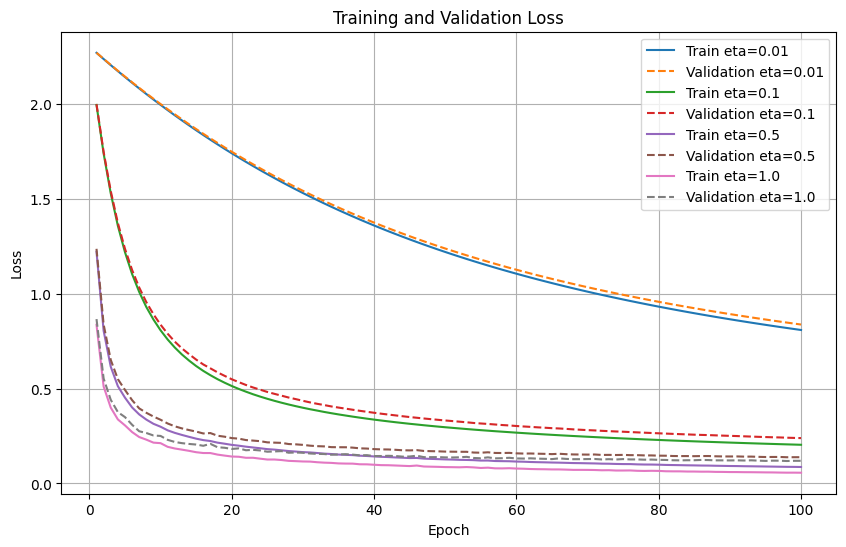

In [ ]:
#Plot the losses
import matplotlib.pyplot as plt

epochs = range(1, 101)

plt.figure(figsize=(10, 6))

for eta in learning_rates:
    history = results[eta]["history"]

    plt.plot(
        epochs,
        history["train_loss"],
        label=f"Train eta={eta}"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        linestyle="--",
        label=f"Validation eta={eta}"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

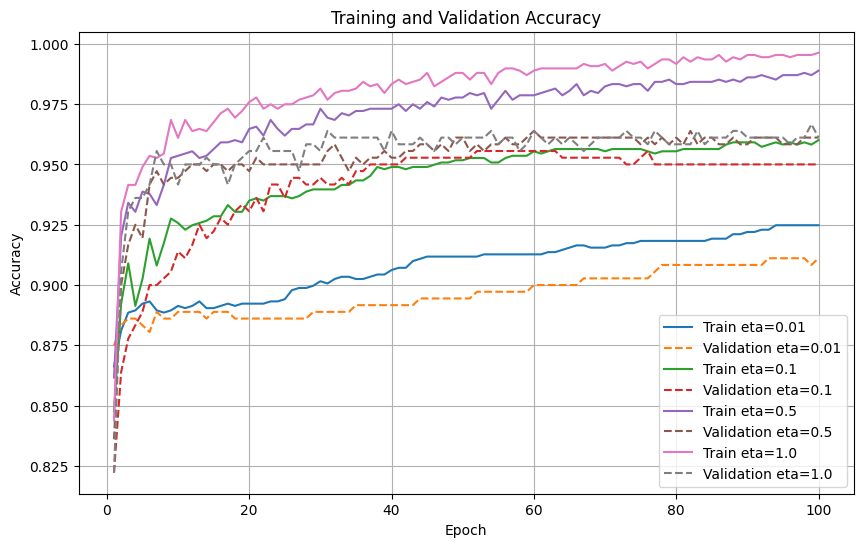

In [ ]:
#plot accurancy
plt.figure(figsize=(10, 6))

for eta in learning_rates:
    history = results[eta]["history"]

    plt.plot(
        epochs,
        history["train_acc"],
        label=f"Train eta={eta}"
    )

    plt.plot(
        epochs,
        history["val_acc"],
        linestyle="--",
        label=f"Validation eta={eta}"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [ ]:
#result table
import pandas as pd

rows = []

for eta in learning_rates:
    history = results[eta]["history"]

    rows.append({
        "Learning Rate": eta,
        "Final Train Loss": history["train_loss"][-1],
        "Final Val Loss": history["val_loss"][-1],
        "Final Train Accuracy": history["train_acc"][-1],
        "Final Val Accuracy": history["val_acc"][-1]
    })

results_table = pd.DataFrame(rows)

print(results_table)

   Learning Rate  Final Train Loss  Final Val Loss  Final Train Accuracy  \
0           0.01          0.808641        0.837388              0.924791   
1           0.10          0.203817        0.238951              0.960074   
2           0.50          0.086785        0.138329              0.988858   
3           1.00          0.056569        0.119327              0.996286   

   Final Val Accuracy  
0            0.911111  
1            0.950000  
2            0.961111  
3            0.961111  


# **Part E: SVM:**

# **Part F: Comparison & Synthesis:**